# 01 — La serie de triage: qué mide y qué no

Este cuaderno describe el desenlace del proyecto: el **conteo de solicitudes de triage** del servicio de urgencias del hospital, día a día y hora a hora, entre el 1 de enero de 2020 y el 20 de septiembre de 2026. Antes de preguntar si un factor externo (clima, eventos, vigilancia en salud) mueve las consultas, hay que saber cómo se comporta la serie por sí sola, porque cualquier efecto externo se mide contra ese comportamiento: su tendencia, su ritmo semanal y diario, sus huecos y sus escalones. Una variable externa que acompañe una tendencia o un escalón que ya existía parecería explicar algo que no explica.

El cuaderno recorre seis aspectos de la serie:

1. Los huecos del registro, para saber qué días no son datos.
2. El volumen: cuánta gente llega, si crece o decrece y cómo es el ciclo anual.
3. El ritmo: la hora, el día de la semana y si esas formas son estables en el tiempo.
4. El tipo de servicio, según el nivel de urgencia asignado en el triage.
5. La caída del volumen desde 2024 y quién la explica.
6. La estancia, y si sirve como medida de saturación.

## Premisas

- El desenlace es **el conteo total de triages** por ventana de tiempo. No se trabaja con el motivo de consulta, con el nivel de urgencia ni con un subgrupo como desenlace; esas variables aparecen aquí solo para entender qué clase de serie es esta.
- Todos los registros se tratan como verídicos: un triage es una persona que sintió la necesidad de consultar, sea cual sea el nivel que le asignaron.
- Un día **sin ninguna fila** en el total no significa cero pacientes, porque urgencias no cierra. Es una caída del registro y se trata como dato ausente (sección 1).

## Cómo leerlo

Cada figura va seguida de su lectura y de sus límites. Toda cifra del texto sale de una salida de este cuaderno, salvo las que se citan expresamente de otro cuaderno.

## De dónde salen los datos

Son agregados de conteo, sin dato personal. El cuaderno no se conecta a ninguna base de datos: se ejecuta entero sobre los archivos de `salidas/`, lo que permite reproducir las figuras sin acceso a la historia clínica.

| Archivo | Qué es | Fuente original | Cómo se regenera |
|---|---|---|---|
| `salidas/triage_horario.parquet` | triages por día × hora | fecha de triage de la tabla de triage de la base del hospital, solo con `GROUP BY` | consulta de conteo única, sin script; se reconstruye sumando `triage_nivel` sobre el nivel |
| `salidas/triage_diario.parquet` | triages por día | ídem | consulta de conteo única, sin script |
| `salidas/triage_nivel.parquet` | día × hora × nivel de urgencia | nivel de clasificación de urgencia del triage | `python -m extraccion --series` |
| `salidas/triage_estancia.parquet` | por día: n, media y máximo de la diferencia entre salida y entrada al servicio | triage unido a la atención | `python -m extraccion --series` |
| `salidas/triage_entidad.parquet` | día × hora × entidad administradora | entidad administradora del plan | `python -m extraccion --entidad`; se agrupa con `extraccion.entidades.clasificar` |
| `calendarios/calendario_Colombia.csv` | festivos, puentes, vacaciones | calendario oficial de Colombia | `python calendarios/calendario_colombia.py` |

**Corte.** Todo se corta el **20 de septiembre de 2026**. El 21 está incompleto en `triage_diario` porque la extracción se hizo a media mañana, y `triage_nivel` y `triage_estancia` llegan a un 22 también parcial.

Como `triage_diario` y `triage_horario` no tienen script, la primera celda comprueba que los agregados son consistentes entre sí: `triage_diario` coincide día a día con la suma de `triage_horario`, y `triage_horario` coincide casilla a casilla con `triage_nivel` y con `triage_entidad` sumados. Así los datos son reproducibles aunque dos de los archivos no se puedan regenerar con un comando.

In [1]:
import sys, pathlib, warnings
RAIZ = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]
            if (p / "CLAUDE.md").exists())
sys.path.insert(0, str(RAIZ)); warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from matplotlib.patches import Patch

from clustering.visualizaciones import datos, figuras
from extraccion.entidades import clasificar

# Paleta de los cuadernos 06 y 07: categóricos en orden fijo
AZUL, NARANJA, AQUA, AMARILLO = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
TINTA, TINTA2, MUDO, SUP = "#0b0b0b", "#52514e", "#898781", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SUP, "axes.facecolor": SUP, "savefig.facecolor": SUP,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUDO,
    "grid.color": "#e6e5e1", "grid.linewidth": .6, "axes.labelcolor": TINTA2,
    "xtick.color": TINTA2, "ytick.color": TINTA2, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlecolor": TINTA, "font.size": 10, "legend.frameon": False})

FIN = "2026-09-20"          # el 21 de septiembre de 2026 está incompleto
def hasta_fin(t):
    t = t.copy(); t["dia"] = pd.to_datetime(t["dia"]); return t[t["dia"] <= FIN]

total    = hasta_fin(datos.marco(datos.total()))                                  # día x hora
diario   = hasta_fin(pd.read_parquet(RAIZ / "salidas" / "triage_diario.parquet")).set_index("dia")["triages"]
nivel    = hasta_fin(pd.read_parquet(RAIZ / "salidas" / "triage_nivel.parquet"))   # día x hora x nivel
estancia = hasta_fin(pd.read_parquet(RAIZ / "salidas" / "triage_estancia.parquet"))
entidad  = hasta_fin(clasificar(pd.read_parquet(RAIZ / "salidas" / "triage_entidad.parquet")))

serie_bruta = datos.serie_diaria(total)          # todos los días del rango; sin filas = NULO
print(f"{total['n'].sum():,} triages   {total['dia'].nunique():,} días con filas de "
      f"{len(serie_bruta):,} del calendario   {serie_bruta.index.min():%Y-%m-%d} a {serie_bruta.index.max():%Y-%m-%d}")

# Tres comprobaciones entre los agregados, que salen de consultas distintas
h = total.groupby("dia")["n"].sum()
cmp = pd.concat([diario, h], axis=1, keys=["diario", "horario"])
print(f"días donde triage_diario != suma de triage_horario: {(cmp.diario != cmp.horario).sum()} de {len(cmp):,}")
a = nivel.groupby(["dia", "hora"])["n"].sum()
b = total.set_index(["dia", "hora"])["n"]
j = pd.concat([a, b], axis=1, keys=["nivel", "horario"]).fillna(0)
print(f"casillas día x hora donde horario != suma de nivel: {(j.nivel != j.horario).sum()} de {len(j):,}")
e = entidad.groupby(["dia", "hora"])["n"].sum()
j2 = pd.concat([e, b], axis=1, keys=["entidad", "horario"]).fillna(0)
print(f"casillas día x hora donde horario != suma de entidad: {(j2.entidad != j2.horario).sum()} de {len(j2):,}")

433,298 triages   2,453 días con filas de 2,455 del calendario   2020-01-01 a 2026-09-20
días donde triage_diario != suma de triage_horario: 0 de 2,453
casillas día x hora donde horario != suma de nivel: 0 de 55,833
casillas día x hora donde horario != suma de entidad: 0 de 55,833


---
# 1. Huecos y caídas del registro

Antes de describir la serie hay que decidir qué días son datos. Se buscan de dos formas:

- **Días sin ninguna fila.** Urgencias no cierra, así que un día sin registros es una caída del sistema y no un día sin pacientes. Van como **nulo**.
- **Días con menos del 40 % de lo esperado, fuera de COVID.** Lo esperado sale de un control de día de la semana, festivos, quincena, vacaciones y nivel de cada año, ajustado en logaritmo fuera del periodo COVID (15 de marzo de 2020 a 28 de febrero de 2022). Como segunda comprobación, sin modelo, se usa la razón contra la mediana del mismo día de la semana en las ±4 semanas.

In [2]:
CAL = ["es_festivo", "es_puente", "es_vispera_festivo", "es_post_festivo", "es_quincena",
       "es_vacaciones_escolares", "es_semana_santa", "es_temporada_navidad",
       "es_temporada_fin_anio", "es_regreso_colegio"]
dias = serie_bruta.index
cal = (pd.read_csv(RAIZ / "calendarios" / "calendario_Colombia.csv", parse_dates=["fecha"])
         .set_index("fecha")[CAL + ["dia_semana"]].apply(pd.to_numeric, errors="coerce")
         .fillna(0).reindex(dias))
Z = pd.concat([pd.get_dummies(cal["dia_semana"].astype(int), prefix="d", drop_first=True).astype(float),
               cal[CAL],
               pd.get_dummies(pd.Index(dias.year), prefix="a", drop_first=True).set_index(dias).astype(float)],
              axis=1)
Z.insert(0, "c", 1.0)
COVID = ("2020-03-15", "2022-02-28")
fuera_covid = ~dias.to_series().between(*COVID).values
ly = np.log(serie_bruta + 0.5)
ok = fuera_covid & serie_bruta.notna().values
beta, *_ = np.linalg.lstsq(Z.values[ok], ly.values[ok], rcond=None)
esperado = pd.Series(np.exp(Z.values @ beta), index=dias)
razon = serie_bruta / esperado

# comprobación sin modelo: mediana del mismo día de la semana en ±4 semanas
mediana = pd.Series(np.nan, index=dias)
for dw in range(7):
    s = serie_bruta[dias.dayofweek == dw]
    mediana[s.index] = s.rolling(9, center=True, min_periods=5).median()
razon2 = serie_bruta / mediana

sin_filas = serie_bruta.index[serie_bruta.isna()]
CAIDOS = razon.index[(razon < 0.4) & fuera_covid]
print("días sin ninguna fila:", [f"{d:%Y-%m-%d}" for d in sin_filas])
print("\nfuera de COVID, por debajo del 40 % de lo esperado:")
for d in CAIDOS:
    print(f"  {d:%Y-%m-%d} ({datos.DIAS[d.dayofweek]})  {serie_bruta[d]:.0f} triages, esperados {esperado[d]:.0f}"
          f"  -> {100*razon[d]:.0f} %   (contra la mediana del mismo día: {100*razon2[d]:.0f} %)")
print("\nsegunda comprobación, por debajo del 40 % de la mediana del mismo día:",
      [f"{d:%Y-%m-%d}" for d in razon2.index[(razon2 < 0.4) & fuera_covid]])
print("para contexto, entre 40 y 60 % de lo esperado:",
      {f"{d:%Y-%m-%d}": f"{100*razon[d]:.0f} %" for d in razon.index[(razon >= .4) & (razon < .6) & fuera_covid]})
print(f"dentro de COVID hay {int(((razon < .4) & ~fuera_covid).sum())} días bajo el 40 %: son el confinamiento, no caídas")

# el 18 y el 22 de marzo de 2024, vecinos del hueco
print("vecinos del hueco:", {f"{d:%d-%b}": int(serie_bruta[d]) for d in pd.to_datetime(["2024-03-18", "2024-03-22"])})

# desde aquí, las caídas parciales cuentan como nulo en el TOTAL
serie = serie_bruta.copy(); serie[CAIDOS] = np.nan
total   = total[~total["dia"].isin(CAIDOS)]
nivel   = nivel[~nivel["dia"].isin(CAIDOS)]
entidad = entidad[~entidad["dia"].isin(CAIDOS)]
print(f"\nserie para el resto del cuaderno: {int(serie.notna().sum()):,} días válidos, {int(serie.isna().sum())} nulos")

días sin ninguna fila: ['2024-03-19', '2024-03-20']

fuera de COVID, por debajo del 40 % de lo esperado:
  2024-03-21 (Jueves)  40 triages, esperados 233  -> 17 %   (contra la mediana del mismo día: 17 %)

segunda comprobación, por debajo del 40 % de la mediana del mismo día: ['2024-03-21']
para contexto, entre 40 y 60 % de lo esperado: {'2026-08-10': '50 %'}
dentro de COVID hay 31 días bajo el 40 %: son el confinamiento, no caídas
vecinos del hueco: {'18-Mar': 285, '22-Mar': 244}

serie para el resto del cuaderno: 2,452 días válidos, 3 nulos


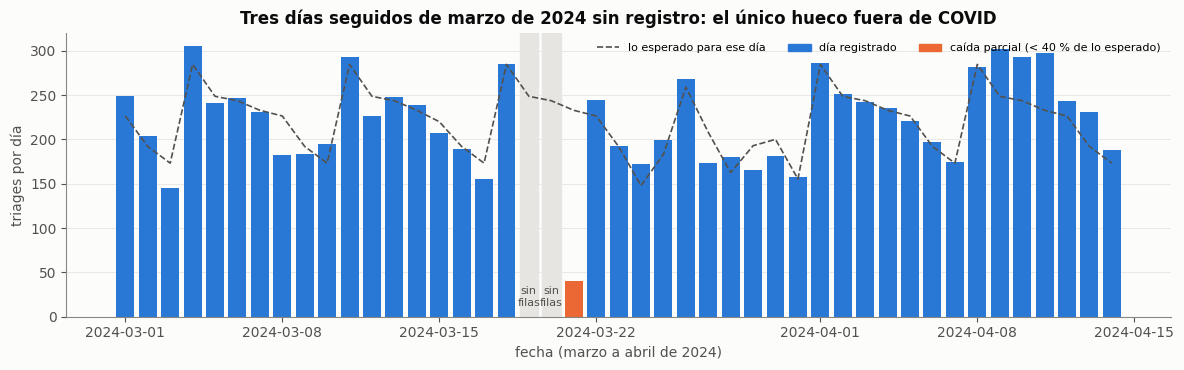

In [3]:
v = serie_bruta.loc["2024-03-01":"2024-04-14"]
fig, ax = plt.subplots(figsize=(12, 3.8))
colores = [NARANJA if d in CAIDOS else AZUL for d in v.index]
ax.bar(v.index, v.fillna(0), color=colores, width=.8)
ax.plot(esperado.loc[v.index].index, esperado.loc[v.index], color=TINTA2, lw=1.2, ls="--", label="lo esperado para ese día")
for d in v.index[v.isna()]:
    ax.axvspan(d - pd.Timedelta(hours=10), d + pd.Timedelta(hours=10), color="#e6e5e1", zorder=0)
    ax.text(d, 12, "sin\nfilas", ha="center", fontsize=8, color=TINTA2)
ax.set_ylabel("triages por día"); ax.set_xlabel("fecha (marzo a abril de 2024)")
ax.set_title("Tres días seguidos de marzo de 2024 sin registro: el único hueco fuera de COVID")
ax.legend(handles=[ax.get_lines()[0], Patch(color=AZUL, label="día registrado"),
                   Patch(color=NARANJA, label="caída parcial (< 40 % de lo esperado)")],
          loc="upper right", ncol=3, fontsize=8)
ax.grid(axis="y"); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()

### Lectura

**Hay un solo hueco de registro y dura tres días.** El 19 y el 20 de marzo de 2024 no tienen ninguna fila, y el 21 tiene 40 triages cuando se esperaban 233 (el 17 %). Es una caída del registro y no de pacientes: el 18 (285 triages) y el 22 (244) son días normales. Los dos criterios, con modelo y sin él, marcan únicamente el 21 de marzo de 2024 como caída parcial fuera de COVID.

- El día más bajo que queda después es el **10 de agosto de 2026, al 50 % de lo esperado**. No se trata como caída del registro: es el día del terremoto, y el cuaderno 06 midió un −50 % ese día. Se conserva.
- Dentro del periodo COVID hay 31 días bajo el 40 %. Son el confinamiento, demanda real que cayó, y tampoco se tocan.

**Regla para el resto del cuaderno.** En el total, un día sin filas es nulo y un día por debajo del 40 % de lo esperado fuera de COVID se excluye; eso deja 2.452 días válidos y 3 nulos. Rellenar con cero sigue siendo correcto para subconjuntos, porque una banda de edad o un asegurador sí pueden tener cero llegadas en un día.

### Límites

- El 40 % es un umbral elegido, no medido. Entre el 40 y el 60 % solo queda el terremoto, así que mover el umbral dentro de ese tramo no cambia nada.
- Una caída del registro que afecte solo una parte del día y deje más del 40 % no se detecta con este criterio.

---
# 2. El volumen

## 2.1 Media diaria por mes y año

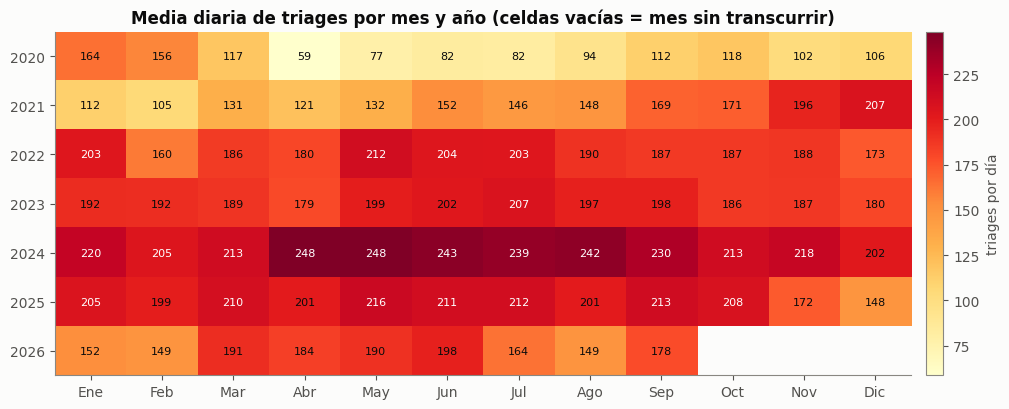

Media diaria por año:
  2020    105.7
  2021    149.3
  2022    189.6
  2023    192.4
  2024    226.9
  2025    199.6
  2026    172.6

Pico: 2024 con 226.9
2026: 172.6  ->  -23.9 % desde el pico

con el archivo tal cual (21-sep-2026 incompleto y 21-mar-2024 dentro): 2024 226.4, 2026 172.3, caída -23.9 %


In [4]:
mat = (serie.groupby([serie.index.year, serie.index.month]).mean().unstack().reindex(columns=range(1, 13)))
fig, ax = plt.subplots(figsize=(11, 4.2))
im = ax.imshow(np.ma.masked_invalid(mat.to_numpy(dtype=float)), aspect="auto", cmap="YlOrRd")
ax.set_xticks(range(12)); ax.set_xticklabels(datos.MESES); ax.set_yticks(range(len(mat))); ax.set_yticklabels(mat.index)
umbral = np.nanpercentile(mat.to_numpy(dtype=float), 70)
for r in range(mat.shape[0]):
    for c in range(12):
        v = mat.to_numpy()[r, c]
        if np.isfinite(v):
            ax.text(c, r, f"{v:.0f}", ha="center", va="center", fontsize=8, color="white" if v > umbral else TINTA)
ax.set_title("Media diaria de triages por mes y año (celdas vacías = mes sin transcurrir)")
fig.colorbar(im, ax=ax, label="triages por día", pad=0.015)
plt.tight_layout(); plt.show()

anual = serie.groupby(serie.index.year).mean()
print("Media diaria por año:")
for a, v in anual.items():
    print(f"  {a}   {v:6.1f}")
print(f"\nPico: {anual.idxmax()} con {anual.max():.1f}")
print(f"2026: {anual.loc[2026]:.1f}  ->  {100*(anual.loc[2026]/anual.max()-1):+.1f} % desde el pico")

vieja = datos.serie_diaria(datos.total())      # el archivo tal cual: con el 21-sep incompleto y el 21-mar-2024
print(f"\ncon el archivo tal cual (21-sep-2026 incompleto y 21-mar-2024 dentro): "
      f"2024 {vieja['2024'].mean():.1f}, 2026 {vieja['2026'].mean():.1f}, "
      f"caída {100*(vieja['2026'].mean()/vieja['2024'].mean()-1):+.1f} %")

### Lectura

**La serie no crece de forma sostenida: sube hasta 2024 y lleva dos años cayendo.** Triages por día, promedio de cada año:

| 2020 | 2021 | 2022 | 2023 | **2024** | 2025 | 2026 |
|---|---|---|---|---|---|---|
| 105,7 | 149,3 | 189,6 | 192,4 | **226,9** | 199,6 | 172,6 |

Desde el pico de 2024, 2026 cae un **23,9 %**. Con el archivo tal cual, sin retirar el 21 de septiembre de 2026 incompleto ni el 21 de marzo de 2024, los promedios de 2024 y 2026 son 226,4 y 172,3 y la caída es la misma, −23,9 %. Dentro de la figura, el máximo mensual es mayo de 2024 y el descenso posterior no es gradual: noviembre y diciembre de 2025 (172 y 148 triages por día) marcan un primer escalón, y luego hay un rebote en marzo de 2026 (191) y otra bajada en julio y agosto (164 y 149).

Esto corrige la lectura de un cuaderno exploratorio inicial, que describía «un aumento progresivo a lo largo de los años». Era una lectura hecha sobre el calendario sin medir la serie completa; con los casi siete años a la vista, el aumento termina en 2024.

### Límites

El promedio anual esconde el escalón: 2025 y 2026 mezclan meses normales con meses de caída fuerte. La sección 5 descompone la caída por asegurador.

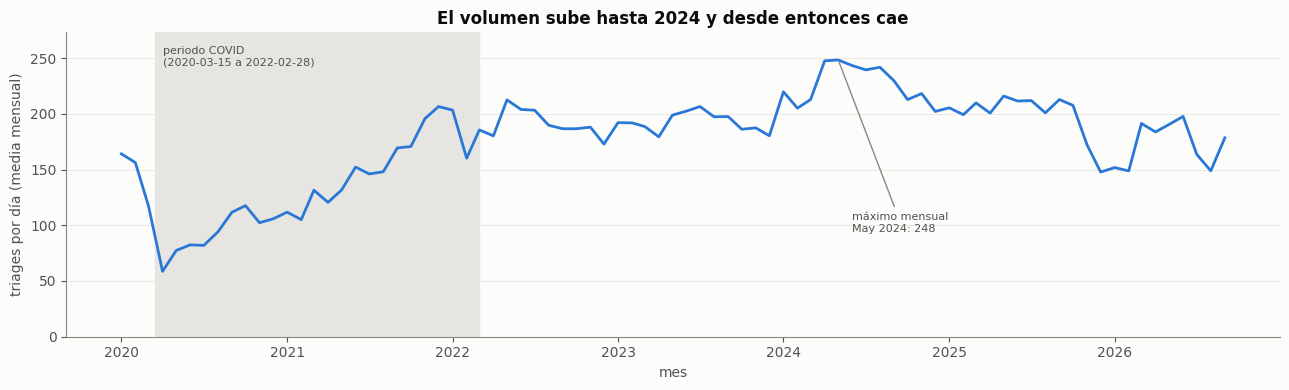

2020: enero 164 -> abril 59  (-64 %)
primer mes que vuelve al nivel de enero de 2020 (164): 2021-09
máximo mensual: 2024-05 con 248.3;   último mes completo (2026-08): 148.8


In [5]:
M = serie.resample("MS").mean()
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(M.index, M.values, color=AZUL, lw=2)
ax.axvspan(pd.Timestamp(COVID[0]), pd.Timestamp(COVID[1]), color="#e6e5e1", zorder=0)
ax.text(pd.Timestamp("2020-04-01"), M.max() * 1.05, "periodo COVID\n(2020-03-15 a 2022-02-28)", fontsize=8, color=TINTA2, va="top")
ax.annotate(f"máximo mensual\n{M.idxmax():%b %Y}: {M.max():.0f}", (M.idxmax(), M.max()),
            xytext=(pd.Timestamp("2024-06-01"), M.max() * 0.38), fontsize=8, color=TINTA2,
            arrowprops=dict(arrowstyle="-", color=MUDO))
ax.set_ylim(0, M.max() * 1.1); ax.set_ylabel("triages por día (media mensual)"); ax.set_xlabel("mes")
ax.set_title("El volumen sube hasta 2024 y desde entonces cae"); ax.grid(axis="y")
plt.tight_layout(); plt.show()

m20 = serie["2020"].groupby(serie["2020"].index.month).mean()
print(f"2020: enero {m20[1]:.0f} -> abril {m20[4]:.0f}  ({100*(m20[4]/m20[1]-1):+.0f} %)")
x = M["2020-05":]
print(f"primer mes que vuelve al nivel de enero de 2020 ({M['2020-01-01']:.0f}): {x[x >= M['2020-01-01']].index[0]:%Y-%m}")
print(f"máximo mensual: {M.idxmax():%Y-%m} con {M.max():.1f};   último mes completo ({M.index[-2]:%Y-%m}): {M.iloc[-2]:.1f}")

### Lectura

**2020 es un cráter de COVID y no un año flojo.** El promedio mensual pasa de 164 triages por día en enero a **59 en abril**, un −64 %, y el volumen no vuelve al nivel de enero de 2020 hasta septiembre de 2021. La parte anterior a marzo de 2022 mezcla por tanto dos cosas: la recuperación de la pandemia y el crecimiento posterior. Por eso 2020 no puede entrar sin tratamiento aparte en el entrenamiento de ningún modelo: le enseñaría una forma anual que no es la del hospital.

Entre marzo de 2022 y diciembre de 2023 la media mensual oscila entre 173 y 212 triages por día; en 2024 sube hasta un máximo mensual de **248,3 en mayo**. El último mes completo, agosto de 2026, tiene 148,8, un 40 % menos que ese máximo.

### Límites

La figura usa medias mensuales y por eso suaviza los escalones de semanas. El desglose por asegurador de la sección 5.2 muestra que el salto de 2024 y la caída posterior son de aseguradores distintos.

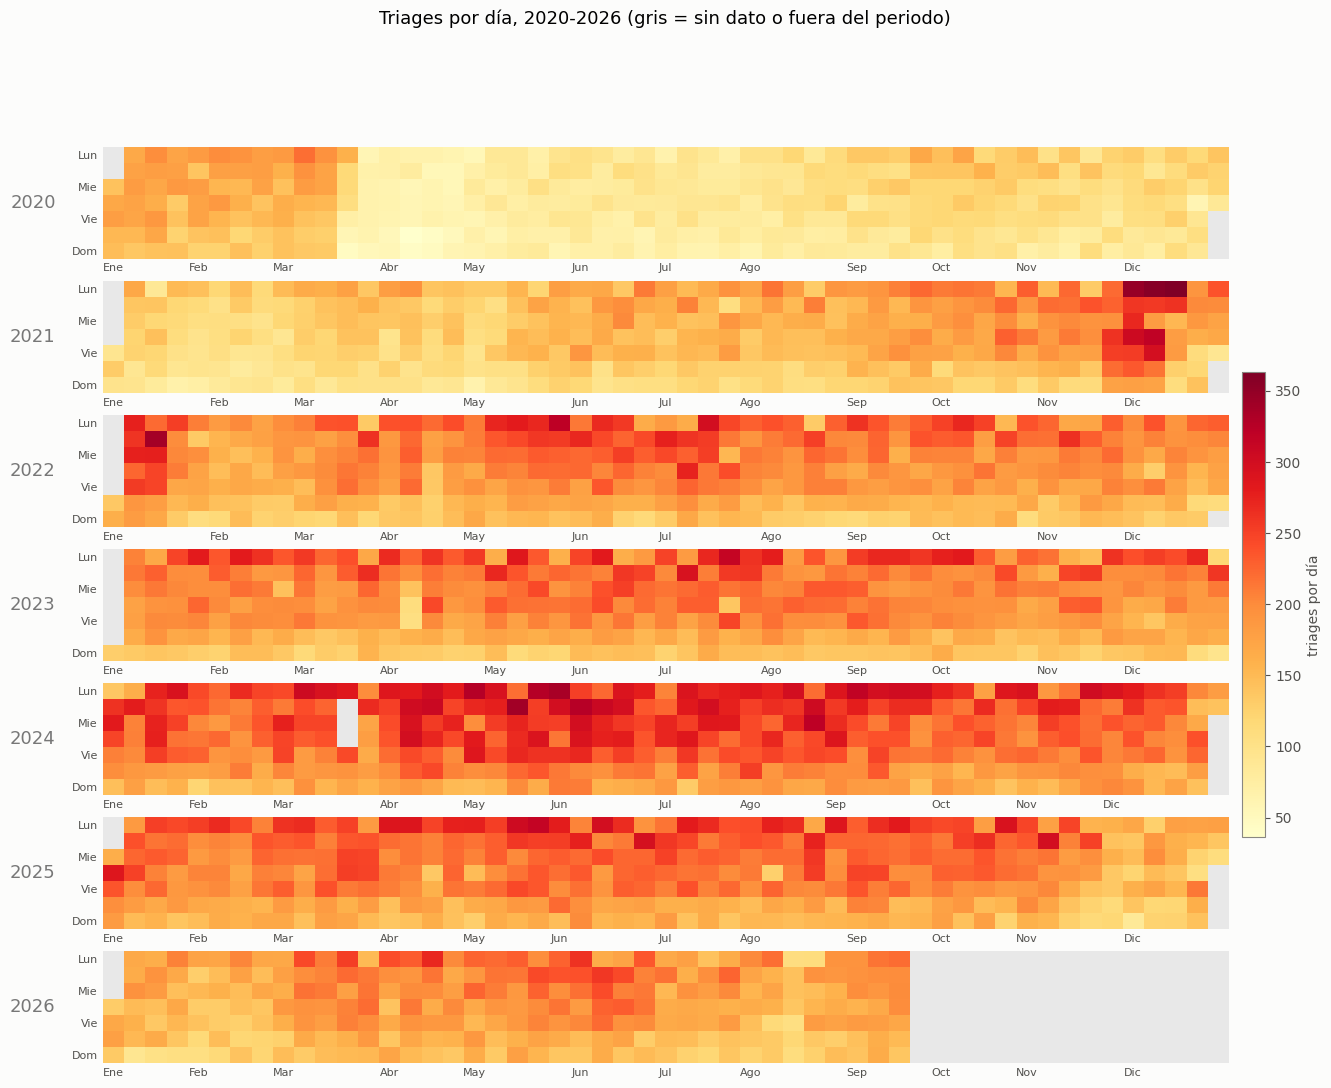

días en gris (nulos) en la figura: ['2024-03-19', '2024-03-20', '2024-03-21']


In [6]:
fig = figuras.calendario(serie, titulo="Triages por día, 2020-2026 (gris = sin dato o fuera del periodo)", etiqueta="triages por día")
plt.show()
print("días en gris (nulos) en la figura:", [f"{d:%Y-%m-%d}" for d in serie.index[serie.isna()]])

## 2.2 El día a día

### Lectura

El calendario muestra tres cosas que la media anual no deja ver:

- **El bloque claro de 2020**, desde mediados de marzo, es el confinamiento. El nivel no se recupera visualmente hasta finales de 2021.
- **La trama vertical constante**: son los domingos, más claros que el resto. El ciclo semanal es tan regular que se ve a simple vista en los siete años.
- **El apagado de 2025-2026 no es gradual sino por tramos**: tonos más claros desde noviembre de 2025 hasta febrero de 2026, un retorno parcial desde marzo y un nuevo aclarado desde julio. La sección 5.2 muestra que esos tramos coinciden con los escalones de un asegurador.

La figura deja en gris tres días seguidos en la tercera semana de marzo de 2024: son los tres días de caída del registro de la sección 1. Las celdas grises al comienzo y al final de cada año son días fuera del año, y las de octubre a diciembre de 2026 son días que no han transcurrido.

### Límites

El color satura en los extremos: un día de 250 y uno de 300 se ven parecidos. Para comparar niveles sirve la figura de la sección 2.1; esta sirve para ver formas y huecos.

In [7]:
def amplitud(s):
    """Meses relativos a la media de su propio año, para que la tendencia no entre en la forma anual."""
    r = s.groupby([s.index.year, s.index.month]).mean().unstack()
    r = r.div(r.mean(axis=1), axis=0).mean()
    return r, 100 * (r.max() / r.min() - 1)

sin2020 = serie[serie.index.year > 2020]
m = sin2020.groupby(sin2020.index.month).mean()
print(f"sin 2020, medias mensuales crudas: pico {datos.MESES[m.idxmax()-1]} {m.max():.0f}, "
      f"valle {datos.MESES[m.idxmin()-1]} {m.min():.0f}, amplitud {100*(m.max()/m.min()-1):.1f} %")
for ini, fin, nota in [("2022", "2024", "2022-2024"), ("2022", "2025", "2022-2025 (incluye el desplome de dic-2025)")]:
    r, amp = amplitud(serie[ini:fin])
    print(f"relativa a la media de cada año, {nota}: pico {datos.MESES[r.idxmax()-1]} {r.max():.3f}, "
          f"valle {datos.MESES[r.idxmin()-1]} {r.min():.3f}, amplitud {amp:.1f} %")
r, _ = amplitud(serie["2022":"2024"])
print("perfil 2022-2024 (1,00 = media del año):", {datos.MESES[k-1]: round(v, 3) for k, v in r.items()})

sin 2020, medias mensuales crudas: pico Jun 202, valle Feb 169, amplitud 19.7 %
relativa a la media de cada año, 2022-2024: pico May 1.083, valle Dic 0.914, amplitud 18.6 %
relativa a la media de cada año, 2022-2025 (incluye el desplome de dic-2025): pico May 1.083, valle Dic 0.870, amplitud 24.4 %
perfil 2022-2024 (1,00 = media del año): {'Ene': 1.014, 'Feb': 0.916, 'Mar': 0.966, 'Abr': 0.992, 'May': 1.083, 'Jun': 1.067, 'Jul': 1.068, 'Ago': 1.031, 'Sep': 1.008, 'Oct': 0.964, 'Nov': 0.976, 'Dic': 0.914}


## 2.3 El ciclo anual

### Lectura

**La estacionalidad anual existe y es modesta: entre el 18 y el 20 % entre el mes más alto y el más bajo.** Con las medias mensuales crudas y sin 2020 el pico es junio (202 triages por día) y el valle febrero (169), una amplitud del 19,7 %. Pero esas medias mezclan la tendencia con el ciclo: 2021 está en plena recuperación y 2025-2026 en caída. Al medir cada mes relativo a la media de su propio año, que quita el nivel y deja la forma, y usando los años 2022 a 2024, el pico pasa a **mayo (1,083 veces la media anual)** y el valle a **diciembre (0,914)**, con febrero casi igual (0,916): amplitud del 18,6 %. De mayo a agosto la demanda está por encima de la media del año (1,083; 1,067; 1,068; 1,031).

Si se amplía el cálculo hasta 2025, la amplitud sube a 24,4 %, pero no es una estacionalidad más fuerte: es el desplome de Nueva EPS de noviembre de 2025 (sección 5.2) metido en el mes de diciembre.

### Límites

- Son tres ciclos anuales completos (2022-2024): cada mes del perfil tiene tres observaciones, así que la forma fina (por ejemplo, si el valle es de diciembre o de febrero) no está establecida.
- La forma anual mezcla el efecto de las vacaciones escolares, los festivos y la quincena con cualquier efecto de clima o de epidemias. Este cuaderno no los separa; el control de calendario del proyecto sí.

---
# 3. El ritmo: la hora pesa más que el día de la semana

## 3.1 Hora × día de la semana

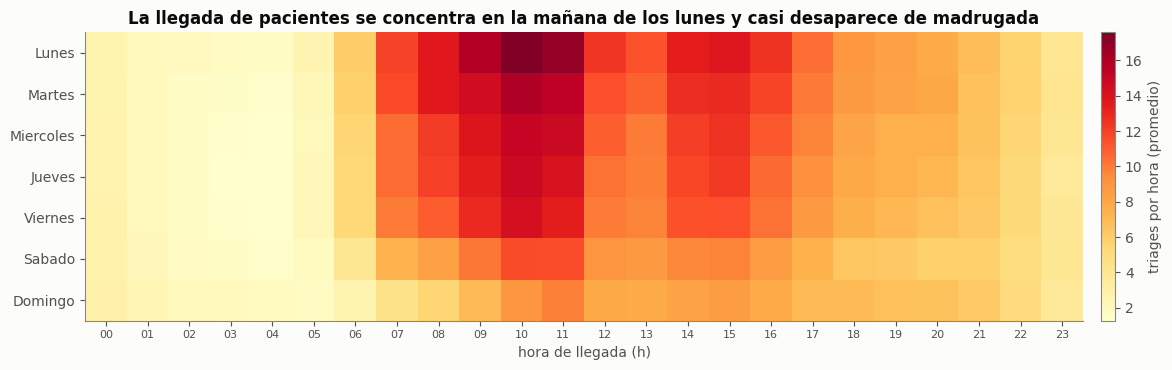

pico  Lunes 10h -> 17.6 triages/h
valle Jueves 03h -> 1.3 triages/h
oscilación hora x día : 13.9x
oscilación semanal    : 1.57x  (Lunes 208.8 -> Domingo 132.7)
media por día de la semana: {'Lunes': 208.8, 'Martes': 198.9, 'Miercoles': 188.0, 'Jueves': 182.5, 'Viernes': 176.2, 'Sabado': 149.9, 'Domingo': 132.7}


In [8]:
nd = total.drop_duplicates("dia").groupby("dow")["dia"].nunique()
med = total.pivot_table(index="dow", columns="hora", values="n", aggfunc="sum").div(nd, axis=0)

fig, ax = plt.subplots(figsize=(13, 3.8))
im = ax.imshow(med.to_numpy(), aspect="auto", cmap="YlOrRd")
ax.set_xticks(range(24)); ax.set_xticklabels([f"{h:02d}" for h in range(24)], fontsize=8)
ax.set_yticks(range(7)); ax.set_yticklabels(datos.DIAS)
ax.set_xlabel("hora de llegada (h)"); ax.set_title("La llegada de pacientes se concentra en la mañana de los lunes y casi desaparece de madrugada")
fig.colorbar(im, ax=ax, label="triages por hora (promedio)", pad=0.015)
plt.tight_layout(); plt.show()

i = np.unravel_index(np.nanargmax(med.to_numpy()), med.shape)
j = np.unravel_index(np.nanargmin(med.to_numpy()), med.shape)
print(f"pico  {datos.DIAS[med.index[i[0]]]} {med.columns[i[1]]:02d}h -> {med.to_numpy()[i]:.1f} triages/h")
print(f"valle {datos.DIAS[med.index[j[0]]]} {med.columns[j[1]]:02d}h -> {med.to_numpy()[j]:.1f} triages/h")
print(f"oscilación hora x día : {med.to_numpy()[i]/med.to_numpy()[j]:.1f}x")

pd_ = serie.groupby(serie.index.dayofweek).mean()
print(f"oscilación semanal    : {pd_.max()/pd_.min():.2f}x  "
      f"({datos.DIAS[pd_.idxmax()]} {pd_.max():.1f} -> {datos.DIAS[pd_.idxmin()]} {pd_.min():.1f})")
print("media por día de la semana:", {datos.DIAS[k]: round(v, 1) for k, v in pd_.items()})

### Lectura

**El pico es el lunes a las 10 h, con 17,6 triages por hora; el valle es el jueves a las 3 h, con 1,3. La oscilación es de 13,9 veces**, frente a 1,57 veces entre el día más cargado y el menos cargado de la semana (lunes, 208,8 triages por día; domingo, 132,7). Los promedios diarios son: lunes 208,8, martes 198,9, miércoles 188,0, jueves 182,5, viernes 176,2, sábado 149,9 y domingo 132,7.

La razón entre las dos oscilaciones (13,9 / 1,57 = 8,9) indica que la hora genera casi nueve veces más variación que el día de la semana. Para un pronóstico por hora, un control de calendario que use solo el día de la semana deja fuera la variable que más pesa.

### Límites

- La razón de oscilaciones no es una medida de información; compara máximos contra mínimos de una rejilla.
- Para un pronóstico diario, la hora no entra: solo cuenta para pronósticos horarios.
- Es el promedio de seis años y medio; la sección 3.3 comprueba si la forma cambió con el tiempo.

## 3.2 La forma del día

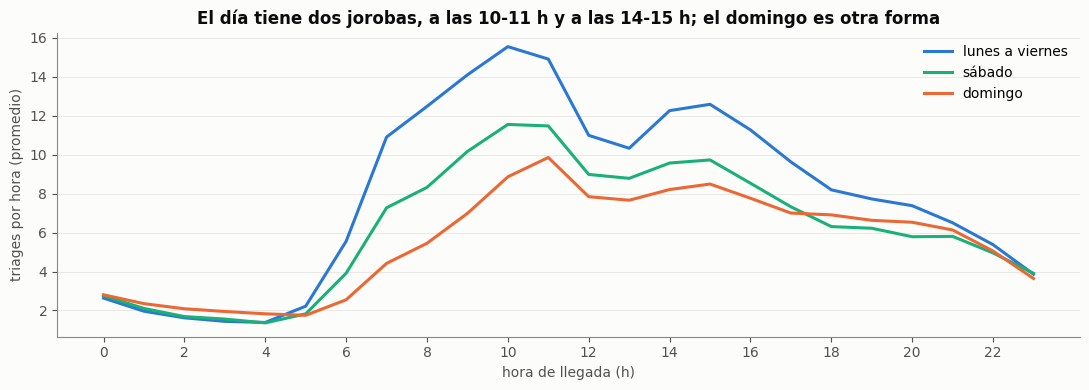

Cuota de la madrugada (00-05h) dentro del día:
  Lunes       5.84%
  Martes      5.64%
  Miercoles   5.80%
  Jueves      5.94%
  Viernes     6.30%
  Sabado      7.52%
  Domingo     9.61%

domingo / jueves = 1.62x   (sin interacción sería 1,00)
varianza que explica el modelo aditivo (día + hora): 97.30%
residuo máximo: 1.69x

Cuota de cada hora en el día medio (%), para ubicar las jorobas:
  06h  2.8  07h  5.4  08h  6.2  09h  7.1  10h  7.9  11h  7.8  12h  5.8  13h  5.5  14h  6.4  15h  6.6  16h  5.9  17h  5.1  18h  4.4  19h  4.2  20h  4.0  21h  3.6  22h  3.0  23h  2.2
madrugada 2-4 h: {'02h': 1.0, '03h': 0.9, '04h': 0.8}

triages por hora, 2022-2026, promedio de todos los días: 10h 15.8   12-13h 10.9   14-15h 12.8   18-19h 8.4


In [9]:
fig, ax = plt.subplots(figsize=(11, 4))
for nombre, filas, col in [("lunes a viernes", [0, 1, 2, 3, 4], AZUL), ("sábado", [5], AQUA), ("domingo", [6], NARANJA)]:
    ax.plot(med.columns, med.loc[filas].mean(), color=col, lw=2.2, label=nombre)
ax.set_xticks(range(0, 24, 2)); ax.set_xlabel("hora de llegada (h)"); ax.set_ylabel("triages por hora (promedio)")
ax.set_title("El día tiene dos jorobas, a las 10-11 h y a las 14-15 h; el domingo es otra forma")
ax.legend(); ax.grid(axis="y")
plt.tight_layout(); plt.show()

forma = med.div(med.sum(axis=1), axis=0)
mad = forma.loc[:, 0:5].sum(axis=1)
print("Cuota de la madrugada (00-05h) dentro del día:")
for d in range(7):
    print(f"  {datos.DIAS[d]:<10} {100*mad[d]:5.2f}%")
print(f"\ndomingo / jueves = {mad[6]/mad[3]:.2f}x   (sin interacción sería 1,00)")

L = np.log(med.to_numpy())
aditivo = L.mean() + (L.mean(axis=1) - L.mean())[:, None] + (L.mean(axis=0) - L.mean())[None, :]
resid = L - aditivo
print(f"varianza que explica el modelo aditivo (día + hora): {100*(1-resid.var()/L.var()):.2f}%")
print(f"residuo máximo: {np.exp(np.abs(resid).max()):.2f}x")

perfil = 100 * med.mean() / med.mean().sum()
print("\nCuota de cada hora en el día medio (%), para ubicar las jorobas:")
print("  " + "  ".join(f"{h:02d}h {v:4.1f}" for h, v in perfil.items() if h >= 6))
print("madrugada 2-4 h:", {f"{h:02d}h": round(perfil[h], 1) for h in (2, 3, 4)})

t22 = total[total["dia"] >= "2022-01-01"]
ph = t22.groupby("hora")["n"].sum() / t22["dia"].nunique()
print(f"\ntriages por hora, 2022-2026, promedio de todos los días: 10h {ph[10]:.1f}   12-13h {ph[[12, 13]].mean():.1f}   14-15h {ph[[14, 15]].mean():.1f}   18-19h {ph[[18, 19]].mean():.1f}")

### Lectura

**El día tiene dos jorobas.** El perfil medido tiene su primer pico a las **10-11 h** (7,9 y 7,8 % de los triages del día), un valle a las **12-13 h** (5,8 y 5,5 %) y un **segundo pico a las 14-15 h** (6,4 y 6,6 %). Desde las 16 h la curva solo baja: a las 18-19 h está en 4,4 y 4,2 %. La madrugada colapsa: 1,0, 0,9 y 0,8 % a las 2, 3 y 4 h. En triages por hora, entre 2022 y 2026, son 15,8 a las 10 h, 10,9 en promedio a las 12-13 h, 12,8 a las 14-15 h y 8,4 a las 18-19 h. La segunda joroba es de primera hora de la tarde y no de la noche.

Para un modelo, esto significa que un solo armónico de 24 h dibuja una sola joroba. Se necesitan al menos dos o tres armónicos, o variables de hora, para describir el ciclo diario.

**Hay además una interacción entre hora y día de la semana.** El modelo aditivo (efecto del día más efecto de la hora, en logaritmo) explica el 97,30 % de la rejilla, casi todo, pero el residuo máximo es de 1,69 veces y no se reparte al azar. La cuota de madrugada (0 a 5 h) dentro del día es:

| | Cuota de la madrugada |
|---|---|
| Jueves | 5,94 % |
| Sábado | 7,52 % |
| **Domingo** | **9,61 %** |

El domingo pesa 1,62 veces más que el jueves en la madrugada. El fin de semana no solo tiene menos volumen: tiene **otra forma**. En la figura, el domingo queda por debajo de los demás días en todas las horas de luz y el contraste con la madrugada es mucho menor.

### Límites

- Las cuotas son promedios de todo el periodo; no distinguen entre tipos de paciente que llegan en cada franja, por lo que la figura no dice por qué el domingo tiene otra forma.

razón lunes/domingo por año: {2020: 1.38, 2021: 1.64, 2022: 1.61, 2023: 1.71, 2024: 1.56, 2025: 1.57, 2026: 1.44}
domingo relativo a la media de su semana, por año: {2020: 0.83, 2021: 0.74, 2022: 0.73, 2023: 0.71, 2024: 0.74, 2025: 0.76, 2026: 0.79}
2022-2024: 1093 días, 202.9 triages/día; cuota 10h 8.2 %  13h 5.5 %  15h 6.6 %
2025-2026: 628 días, 188.3 triages/día; cuota 10h 7.6 %  13h 5.4 %  15h 6.6 %


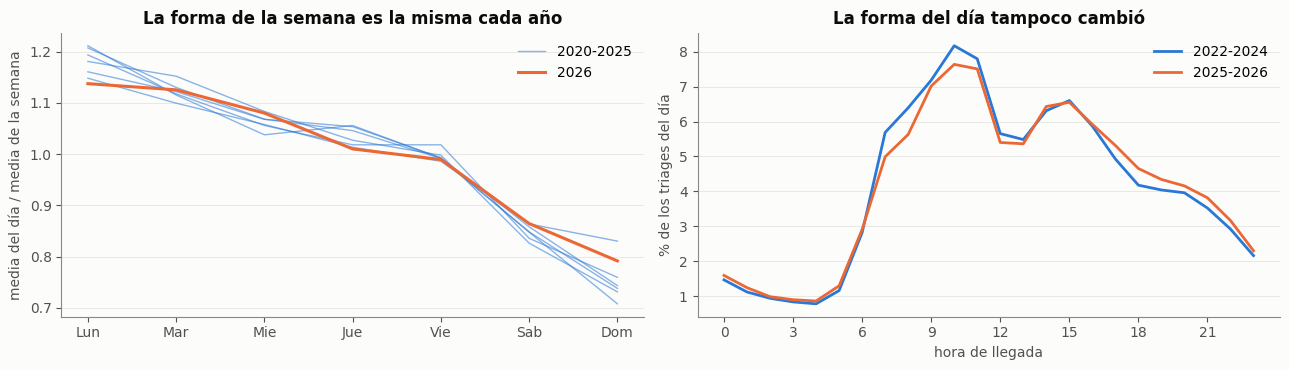

diferencia máxima entre las dos curvas horarias (puntos de cuota): 0.76


In [10]:
# ¿La forma semanal y la forma del día son estables entre años?
dw = serie.groupby([serie.index.year, serie.index.dayofweek]).mean().unstack()
rel = dw.div(dw.mean(axis=1), axis=0)
print("razón lunes/domingo por año:", (dw[0] / dw[6]).round(2).to_dict())
print("domingo relativo a la media de su semana, por año:", rel[6].round(2).to_dict())

per = {"2022-2024": ("2022-01-01", "2024-12-31"), "2025-2026": ("2025-01-01", "2026-09-20")}
forma_h = {}
for nombre, (a0, a1) in per.items():
    t = total[(total["dia"] >= a0) & (total["dia"] <= a1)]
    p = t.groupby("hora")["n"].sum() / t["dia"].nunique()
    forma_h[nombre] = 100 * p / p.sum()
    print(f"{nombre}: {t['dia'].nunique()} días, {p.sum():.1f} triages/día; cuota 10h {forma_h[nombre][10]:.1f} %  "
          f"13h {forma_h[nombre][13]:.1f} %  15h {forma_h[nombre][15]:.1f} %")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 3.8))
for y in rel.index:
    a1.plot(range(7), rel.loc[y], lw=2.2 if y == 2026 else 1.0, color=NARANJA if y == 2026 else AZUL,
            alpha=1 if y == 2026 else .55, label="2026" if y == 2026 else ("2020-2025" if y == 2020 else None))
a1.set_xticks(range(7)); a1.set_xticklabels([d[:3] for d in datos.DIAS])
a1.set_ylabel("media del día / media de la semana"); a1.set_title("La forma de la semana es la misma cada año")
a1.legend(); a1.grid(axis="y")
for (nombre, s), col in zip(forma_h.items(), (AZUL, NARANJA)):
    a2.plot(s.index, s.values, color=col, lw=2, label=nombre)
a2.set_xlabel("hora de llegada"); a2.set_ylabel("% de los triages del día")
a2.set_title("La forma del día tampoco cambió"); a2.legend(); a2.grid(axis="y")
a2.set_xticks(range(0, 24, 3))
plt.tight_layout(); plt.show()
print("diferencia máxima entre las dos curvas horarias (puntos de cuota):", round((forma_h["2022-2024"] - forma_h["2025-2026"]).abs().max(), 2))

## 3.3 ¿Cambian estas formas con el tiempo?

### Lectura

**La forma semanal y la forma del día son estables entre años, con una variación en 2026.** La razón lunes/domingo es 1,64, 1,61, 1,71, 1,56 y 1,57 entre 2021 y 2025; en 2020 (confinamiento) es 1,38 y en 2026, 1,44. En 2026 baja porque el domingo pesa más: relativo a la media de su semana pasa de 0,71-0,76 entre 2021 y 2025 a 0,79 en 2026. Es un cambio pequeño, que coincide en el tiempo con la caída de Nueva EPS, pero este cuaderno no puede atribuirlo a esa causa porque no cruza día de la semana con asegurador.

En la forma del día, las curvas de 2022-2024 y 2025-2026 tienen las dos jorobas en las mismas horas. La mayor diferencia es de 0,76 puntos de cuota y está en el pico de las 10 h (8,2 % frente a 7,6 %); a las 13 y a las 15 h las cuotas son casi iguales (5,5 y 5,4 %; 6,6 y 6,6 %).

### Límites

La estabilidad de la forma no implica estabilidad del nivel: el volumen por día pasó de 202,9 triages en 2022-2024 a 188,3 en 2025-2026 sin que la forma se alterara de manera apreciable. El volumen de 2025-2026 también incluye los dos escalones de la sección 5.

---
# 4. Qué clase de servicio es

El nivel de urgencia está presente en **todos** los registros del periodo (433.258 con el corte de este cuaderno). No depende del texto ni de ningún modelo: lo asigna el personal en el momento del triage.

In [11]:
print(f"registros con nivel: {nivel['n'].sum():,}")
resumen = (nivel.groupby(["nivel", "nivel_nombre"])["n"].sum()
           .sort_values(ascending=False).reset_index())
resumen["cuota"] = 100 * resumen["n"] / resumen["n"].sum()
print(f"{'nivel':<8}{'descripción':<42}{'n':>10}{'cuota':>8}")
for _, r in resumen.head(10).iterrows():
    print(f"{r.nivel:<8}{str(r.nivel_nombre)[:40]:<42}{r.n:>10,}{r.cuota:>7.1f}%")

GRUPO = {"I": "urgente", "II": "urgente", "I-G": "urgente", "II-G": "urgente",
         "IIIU": "urgencia", "III": "diferido", "III-G": "diferido",
         "IV": "no urgente", "IV-G": "no urgente",
         "V": "consulta externa", "V-G": "consulta externa"}
nivel["grupo"] = nivel["nivel"].map(GRUPO).fillna("otro")
g = nivel.groupby("grupo")["n"].sum()
g = 100 * g / g.sum()
print(f"\n  urgencia real (I, II)     {g.get('urgente', 0):5.1f}%")
print(f"  urgencia (IIIU)           {g.get('urgencia', 0):5.1f}%")
print(f"  diferido (III)            {g.get('diferido', 0):5.1f}%")
print(f"  NO urgente (IV) + externa {g.get('no urgente', 0) + g.get('consulta externa', 0):5.1f}%")

n_niv = nivel.groupby("nivel")["n"].sum(); N = n_niv.sum()
print(f"\n  solo IV + V               {100*(n_niv['IV'] + n_niv['V'])/N:5.1f}%")
print(f"  urgencia médica II + II-G {100*(n_niv['II'] + n_niv['II-G'])/N:5.1f}%")
print(f"  emergencia I + I-G        {n_niv['I'] + n_niv['I-G']:,} casos ({n_niv['I']:,} + {n_niv['I-G']:,}) = {100*(n_niv['I'] + n_niv['I-G'])/N:.2f}%")
print(f"  obstétrico (sufijo -G)    {100*n_niv[[k for k in n_niv.index if k.endswith('-G')]].sum()/N:5.1f}%")

registros con nivel: 433,258
nivel   descripción                                        n   cuota
IV      DIFERIDA/NO URGENTE                          169,651   39.2%
IIIU    URGENCIA                                     106,550   24.6%
V       CONSULTA EXTERNA                              52,986   12.2%
III-G   URGENCIA OBSTETRICA DIFERIDA O MENOR          47,285   10.9%
III     DIFERIDA                                      41,693    9.6%
II      URGENCIA MEDICA                                6,477    1.5%
II-G    URGENCIA MEDICA OBSTETRICA                     6,296    1.5%
I       EMERGENCIA                                     1,460    0.3%
M       MUERTO                                           285    0.1%
IV-G    NO URGENTE OBSTETRICA                            265    0.1%

  urgencia real (I, II)       3.3%
  urgencia (IIIU)            24.6%
  diferido (III)             20.5%
  NO urgente (IV) + externa  51.5%

  solo IV + V                51.4%
  urgencia médica II + II-G   2.9%


### Lectura

| Nivel | Qué es | Cuota |
|---|---|---|
| IV | Diferida / no urgente | **39,2 %** |
| IIIU | Urgencia | 24,6 % |
| V | Consulta externa | 12,2 % |
| III-G | Urgencia obstétrica diferida | 10,9 % |
| III | Diferida | 9,6 % |
| II + II-G | Urgencia médica | 2,9 % |
| **I + I-G** | **Emergencia** | **0,37 %** |

**Más de la mitad de los triages son no urgentes (IV + V = 51,4 %), y las emergencias son 1.591 casos (0,37 %) en casi siete años.** El componente obstétrico (niveles con sufijo -G) es el 12,5 %.

El servicio no es, por tanto, un servicio de emergencias graves. Con la mitad de las consultas en categorías no urgentes, la demanda puede variar por razones que no pasan por la gravedad (la incapacidad del día, un evento, el cambio de asegurador), y por eso tiene sentido buscar factores externos en el conteo total. El análisis de este cuaderno no prueba que esos factores operen. Según el contexto institucional, además, el hospital recibe todo tipo de urgencias y las que no puede resolver las estabiliza y las remite, de modo que el conteo mide la puerta de entrada y no solo la patología que el hospital resuelve.

### Límites

- El nivel lo asigna una persona con un criterio, y ese criterio cambió en el tiempo (sección 5.1). Mide lo que el hospital decide hacer con el paciente, no su gravedad.
- La agrupación de niveles en cinco grupos es una convención de este cuaderno.

---
# 5. La caída del volumen desde 2024

El volumen cayó un 23,9 % desde el pico de 2024. Se pregunta de dos maneras: si cambió la forma en que se clasifica (composición por nivel de urgencia) y quién dejó de venir (composición por asegurador). Hay que distinguir bien qué puede contestar cada una. Que los niveles se reparten de otra forma no dice nada sobre el conteo, porque un paciente reclasificado de nivel IV a nivel III sigue siendo un triage. La composición por nivel dice si el criterio cambió; solo la composición por asegurador puede decir quién dejó de venir.

## 5.1 La composición por nivel

In [12]:
anual = nivel.assign(anio=nivel["dia"].dt.year).pivot_table(
    index="anio", columns="grupo", values="n", aggfunc="sum").fillna(0)
orden = ["urgente", "urgencia", "diferido", "no urgente", "consulta externa"]
anual = anual[[c for c in orden if c in anual.columns]]

print("CUOTA POR AÑO (%)")
print((100 * anual.div(anual.sum(axis=1), axis=0)).round(1).to_string())

dias_2026 = nivel.loc[nivel["dia"].dt.year == 2026, "dia"].nunique()
print(f"\nCAMBIO 2024 -> 2026 (2026 anualizado con {dias_2026} días)")
a, b = anual.loc[2024], anual.loc[2026] * 365 / dias_2026
for c in anual.columns:
    print(f"  {c:<18}{a[c]:>9,.0f} ->{b[c]:>9,.0f}   {100*(b[c]/a[c]-1):+7.1f}%")
print(f"  {'TOTAL':<18}{a.sum():>9,.0f} ->{b.sum():>9,.0f}   {100*(b.sum()/a.sum()-1):+7.1f}%")

mes_total = nivel.assign(ym=nivel["dia"].dt.to_period("M")).groupby("ym")["n"].sum()
print("\ntriages por mes, sep-2025 a ene-2026:", {str(k): int(v) for k, v in mes_total.loc["2025-09":"2026-01"].items()})

CUOTA POR AÑO (%)
grupo  urgente  urgencia  diferido  no urgente  consulta externa
anio                                                            
2020       5.9      34.9      23.6        19.4              16.2
2021       3.9      29.0      20.9        35.2              10.9
2022       3.1      24.4      14.8        45.5              12.2
2023       2.3      25.4      15.4        46.5              10.4
2024       1.9      21.2      14.3        48.4              14.1
2025       3.3      21.5      25.4        37.2              12.6
2026       4.8      20.9      37.7        26.9               9.7

CAMBIO 2024 -> 2026 (2026 anualizado con 263 días)
  urgente               1,600 ->    3,020     +88.7%
  urgencia             17,450 ->   13,147     -24.7%
  diferido             11,809 ->   23,726    +100.9%
  no urgente           39,850 ->   16,944     -57.5%
  consulta externa     11,599 ->    6,125     -47.2%
  TOTAL                82,308 ->   62,962     -23.5%

triages por mes, sep-2025 

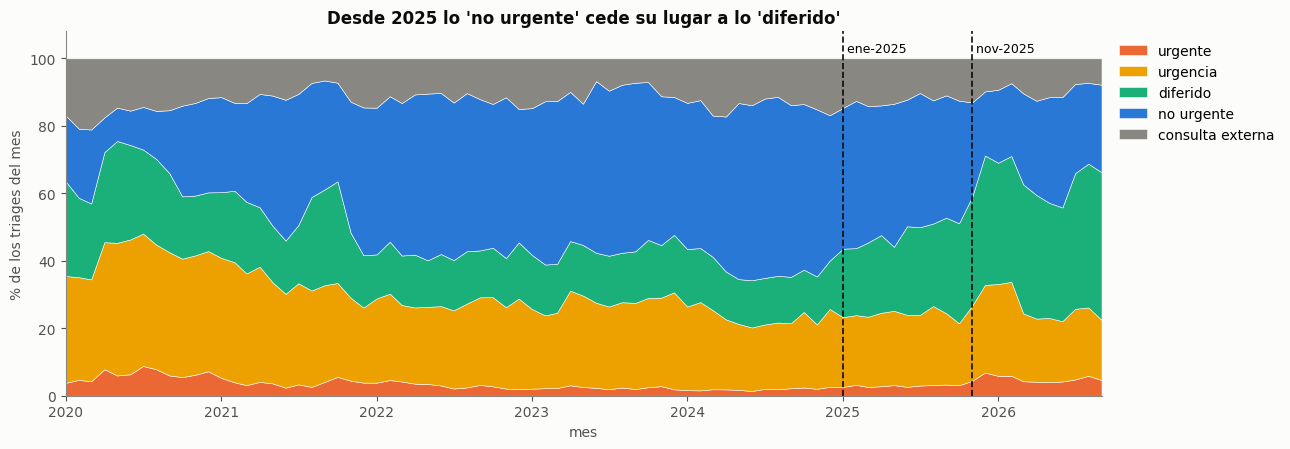

In [13]:
mensual = nivel.assign(ym=nivel["dia"].dt.to_period("M")).pivot_table(
    index="ym", columns="grupo", values="n", aggfunc="sum").fillna(0)
mensual = mensual[[c for c in orden if c in mensual.columns]]
cuota = 100 * mensual.div(mensual.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(13, 4.6))
cols = {"urgente": NARANJA, "urgencia": AMARILLO, "diferido": AQUA, "no urgente": AZUL, "consulta externa": MUDO}
ax.stackplot(cuota.index.to_timestamp(), cuota.to_numpy().T, labels=cuota.columns,
             colors=[cols[c] for c in cuota.columns], edgecolor=SUP, linewidth=.4)
for f, t in [("2025-01-01", "ene-2025"), ("2025-11-01", "nov-2025")]:
    ax.axvline(pd.Timestamp(f), color=TINTA, lw=1.2, ls="--")
    ax.text(pd.Timestamp(f), 102, " " + t, fontsize=9)
ax.set_ylim(0, 108); ax.set_xlim(cuota.index.to_timestamp().min(), cuota.index.to_timestamp().max())
ax.set_ylabel("% de los triages del mes"); ax.set_xlabel("mes")
ax.set_title("Desde 2025 lo 'no urgente' cede su lugar a lo 'diferido'")
ax.legend(loc="upper left", bbox_to_anchor=(1.005, 1))
plt.tight_layout(); plt.show()

### Lectura

**El criterio de clasificación cambió: la cuota de cada nivel se movió en direcciones opuestas desde 2025.** La cuota de «no urgente» pasa del 48,4 % en 2024 al 37,2 % en 2025 y al 26,9 % en 2026, mientras «diferido» sube del 14,3 al 25,4 y al 37,7 %, y «urgente» (I y II) del 1,9 al 3,3 y al 4,8 %. Entre 2024 y 2026, con 2026 llevado a un año con sus 263 días, los cambios son: diferido +100,9 %, urgente +88,7 %, urgencia (IIIU) −24,7 %, no urgente −57,5 %, consulta externa −47,2 % y total −23,5 %. El total es −23,5 % y no −23,9 % porque en el total anual de 2024 faltan los tres días nulos de marzo, que no se anualizan.

La deriva arranca en enero de 2025, antes de que caiga el volumen, y se acelera desde noviembre de 2025, cuando el total mensual pasa de 6.434 (octubre) a 5.165 (noviembre) y 4.581 (diciembre).

**Qué dice y qué no.**

- La deriva de enero a octubre de 2025 ocurre con la cuota de Nueva EPS estable o creciendo (sección 5.3), así que no se explica por un cambio de quién llega. Su causa (una directriz, un cambio de contrato, una auditoría) no está en los datos.
- Desde noviembre de 2025 cambian a la vez el criterio y el asegurador que más cae. Sin un cruce de nivel por asegurador no se puede decir cuánto de la subida de «urgente» y «diferido» es reclasificación y cuánto es un cambio de composición de pacientes.
- El nivel de urgencia no es comparable entre años: un triage IV de 2024 y uno de 2026 no son lo mismo. Sirve para describir el hospital y para separar poblaciones dentro de un periodo corto.
- La ventana en que existe texto de motivo de consulta (2025 en adelante) es la misma en que deriva el criterio, de modo que cualquier serie por motivo hereda este cambio.

### Límites

La agrupación en cinco categorías mezcla niveles ordinarios y obstétricos. La figura es de composición porcentual, por lo que no muestra el volumen: un nivel puede perder cuota porque otro creció.

## 5.2 Quién explica la caída del volumen: Nueva EPS

Con la entidad administradora del plan se puede partir el conteo por quién paga. Se compara **Nueva EPS** con **todo lo demás** (EPS Sura, otras EPS, SOAT, ARL, particulares). La agrupación de entidades se hace por reglas sobre el nombre y está en `salidas/entidades_clasificadas.csv`.

Como contexto institucional, que este cuaderno no mide: la Superintendencia de Salud intervino Nueva EPS el 3 de abril de 2024, y según el hospital sus afiliados dejaron de consultar porque no esperan que los atiendan.

In [14]:
g = entidad.pivot_table(index="dia", columns="grupo", values="n", aggfunc="sum").reindex(serie.index).fillna(0)
nueva = g["nueva_eps"].where(serie.notna())
resto = serie - nueva
sura  = g["sura_eps"].where(serie.notna())

A = pd.DataFrame({"total": serie, "Nueva EPS": nueva, "resto": resto, "de ello Sura": sura})
tabla = A.groupby(A.index.year).mean()
tabla["% Nueva EPS"] = 100 * tabla["Nueva EPS"] / tabla["total"]
print("TRIAGES POR DÍA, MEDIA DEL AÑO")
print(tabla.round(1).to_string())

print("\nDE DÓNDE SALE CADA CAMBIO (triages por día)")
for a0, a1 in [(2024, 2025), (2025, 2026), (2024, 2026)]:
    d = tabla.loc[a1] - tabla.loc[a0]
    print(f"  {a0} -> {a1}: total {d.total:+6.1f}   Nueva EPS {d['Nueva EPS']:+6.1f}   resto {d.resto:+6.1f}")

sem = A[["Nueva EPS", "resto"]].resample("W-SAT").mean()
print("\nNueva EPS por semana alrededor de los dos desplomes (triages/día, semana que termina en):")
for a0, a1 in [("2025-10-25", "2025-12-13"), ("2026-06-06", "2026-07-25")]:
    print("  " + "  ".join(f"{d:%d-%b-%y} {v:5.1f}" for d, v in sem.loc[a0:a1, "Nueva EPS"].items()))

# El salto de Sura de abril de 2024, mes a mes
mm = A[["Nueva EPS", "de ello Sura", "resto"]].resample("MS").mean()
print("\nmedia mensual ene-ago 2024 (triages/día):")
print(mm.loc["2024-01":"2024-08"].round(1).to_string())
sura_antes, sura_despues = mm.loc["2024-01":"2024-03", "de ello Sura"].mean(), mm.loc["2024-05":"2024-07", "de ello Sura"].mean()
ne_antes, ne_despues = mm.loc["2024-01":"2024-03", "Nueva EPS"].mean(), mm.loc["2024-05":"2024-07", "Nueva EPS"].mean()
print(f"Sura  ene-mar -> may-jul 2024: {sura_antes:.1f} -> {sura_despues:.1f} ({sura_despues - sura_antes:+.1f});   "
      f"Nueva EPS: {ne_antes:.1f} -> {ne_despues:.1f} ({ne_despues - ne_antes:+.1f})")

# Los dos desplomes como episodios: cuatro semanas antes y cuatro después, y cuánto compensa el resto
EP = {"nov-2025": (("2025-09-28", "2025-10-25"), ("2025-11-29", "2025-12-26")),
      "jul-2026": (("2026-05-24", "2026-06-20"), ("2026-07-11", "2026-08-07"))}
print("\nEPISODIOS (4 semanas antes y 4 semanas después, triages/día)")
for nom, (ant, des) in EP.items():
    p, q = A.loc[ant[0]:ant[1]].mean(), A.loc[des[0]:des[1]].mean()
    dne, dr, dt = q["Nueva EPS"] - p["Nueva EPS"], q["resto"] - p["resto"], q["total"] - p["total"]
    print(f"  {nom}: Nueva EPS {p['Nueva EPS']:.1f} -> {q['Nueva EPS']:.1f} ({dne:+.1f});  resto {p['resto']:.1f} -> {q['resto']:.1f} ({dr:+.1f});  "
          f"total {p['total']:.1f} -> {q['total']:.1f} ({100*dt/p['total']:+.1f} %);  el resto compensa el {100*dr/-dne:.0f} %")

TRIAGES POR DÍA, MEDIA DEL AÑO
      total  Nueva EPS  resto  de ello Sura  % Nueva EPS
2020  105.7       64.8   40.9           8.6         61.3
2021  149.3       86.1   63.3          16.8         57.6
2022  189.6      125.3   64.3          28.5         66.1
2023  192.4      122.9   69.5          41.1         63.9
2024  226.9      125.6  101.3          69.6         55.4
2025  199.6      115.8   83.8          53.9         58.0
2026  172.6       72.2  100.4          62.0         41.8

DE DÓNDE SALE CADA CAMBIO (triages por día)
  2024 -> 2025: total  -27.2   Nueva EPS   -9.8   resto  -17.4
  2025 -> 2026: total  -27.0   Nueva EPS  -43.6   resto  +16.6
  2024 -> 2026: total  -54.2   Nueva EPS  -53.4   resto   -0.9

Nueva EPS por semana alrededor de los dos desplomes (triages/día, semana que termina en):
  25-Oct-25 136.0  01-Nov-25 125.6  08-Nov-25 116.9  15-Nov-25 105.4  22-Nov-25  85.9  29-Nov-25  59.3  06-Dec-25  54.7  13-Dec-25  61.7
  06-Jun-26  98.9  13-Jun-26 100.9  20-Jun-26  98.0

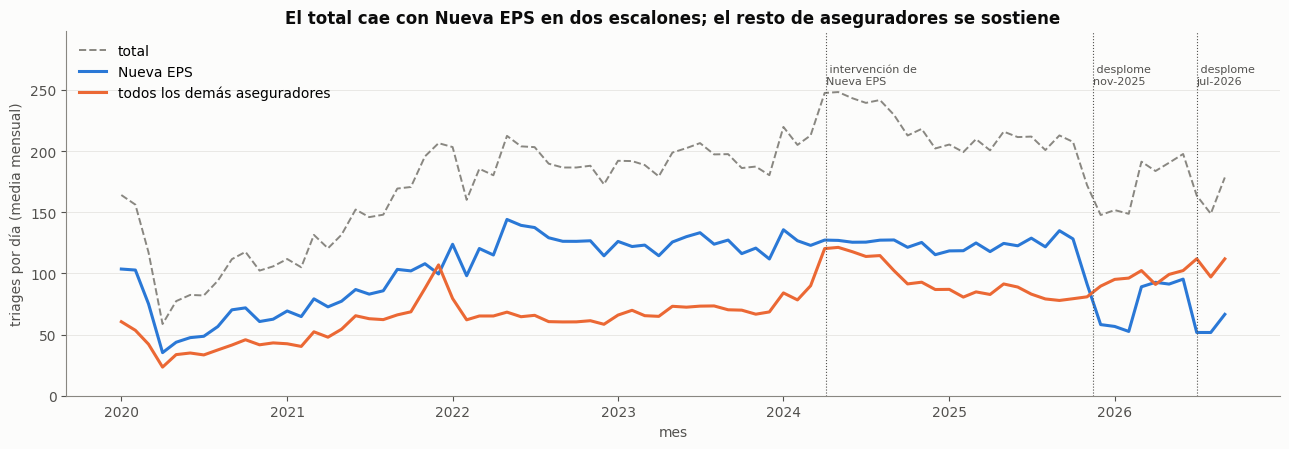

In [15]:
M = A[["total", "Nueva EPS", "resto"]].resample("MS").mean()
fig, ax = plt.subplots(figsize=(13, 4.6))
ax.plot(M.index, M["total"], color=MUDO, lw=1.4, ls="--", label="total")
ax.plot(M.index, M["Nueva EPS"], color=AZUL, lw=2.2, label="Nueva EPS")
ax.plot(M.index, M["resto"], color=NARANJA, lw=2.2, label="todos los demás aseguradores")
tope = M["total"].max()
for f, t in [("2024-04-03", "intervención de\nNueva EPS"), ("2025-11-15", "desplome\nnov-2025"),
             ("2026-07-01", "desplome\njul-2026")]:
    ax.axvline(pd.Timestamp(f), color=TINTA2, lw=.8, ls=":")
    ax.text(pd.Timestamp(f), tope * 1.02, " " + t, fontsize=8, color=TINTA2, va="bottom")
ax.set_ylim(0, tope * 1.2); ax.grid(axis="y")
ax.set_ylabel("triages por día (media mensual)"); ax.set_xlabel("mes")
ax.set_title("El total cae con Nueva EPS en dos escalones; el resto de aseguradores se sostiene")
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

### Lectura

**La caída desde 2024 es, casi entera, de Nueva EPS; el pico de 2024, en cambio, no.** Triages por día (salida de la celda):

| | 2022 | 2023 | 2024 | 2025 | 2026 |
|---|---|---|---|---|---|
| Total | 189,6 | 192,4 | 226,9 | 199,6 | 172,6 |
| **Nueva EPS** | 125,3 | 122,9 | 125,6 | 115,8 | **72,2** |
| Todos los demás | 64,3 | 69,5 | 101,3 | 83,8 | 100,4 |
| de ello EPS Sura | 28,5 | 41,1 | 69,6 | 53,9 | 62,0 |
| % Nueva EPS | 66,1 | 63,9 | 55,4 | 58,0 | 41,8 |

- **De 2024 a 2026 el total pierde 54,2 triages por día y Nueva EPS pierde 53,4.** El resto de aseguradores queda prácticamente igual (−0,9).
- **Los dos tramos de la caída son distintos.** De 2024 a 2025 (−27,2) la mayor parte es del resto (−17,4) y, dentro de él, de EPS Sura (69,6 a 53,9); Nueva EPS pierde 9,8. De 2025 a 2026 (−27,0), Nueva EPS pierde 43,6 y el resto sube 16,6 sin compensarlo.
- **El salto de 2024 es de EPS Sura y no de Nueva EPS.** De 2023 a 2024 el total sube 34,5 triages por día: Nueva EPS aporta 2,7 y el resto 31,8. Mes a mes, Sura pasa de 59,0 en marzo a 91,9 en abril de 2024; entre el trimestre enero-marzo y el trimestre mayo-julio sube de 52,1 a 81,4 (+29,4) mientras Nueva EPS pasa de 128,5 a 126,0 (−2,4). El cuaderno 18 mide el mismo escalón de Sura con otras ventanas. El pico de 2024 y la caída posterior son, por tanto, dos historias de dos aseguradores distintos.
- **Los cambios de Nueva EPS son escalones, no una pendiente.** Estable en unos 120-135 triages por día hasta octubre de 2025, cae en la segunda quincena de noviembre de 2025 (de 136,0 en la semana que termina el 25 de octubre a 59,3 la del 29 de noviembre), se recupera en marzo de 2026 y vuelve a caer la primera semana de julio de 2026 (de 98,0 a 59,9 entre las semanas del 20 de junio y del 4 de julio). El desplome de noviembre comienza antes del 1 de diciembre (105,4 la semana del 15 de noviembre y 85,9 la del 22).
- **El resto de aseguradores compensa poco.** En cuatro semanas antes y después, en noviembre de 2025 Nueva EPS baja de 129,5 a 58,3 (−71,2) y el resto sube 9,0, lo que compensa el 13 %; el total cae un 29,9 %. En julio de 2026, Nueva EPS baja de 99,0 a 49,8 (−49,2) y el resto sube 10,9, el 22 %; el total cae un 19,2 %. El cuaderno 18 mide la compensación con otras ventanas y obtiene 16 % y 11 %: el orden de magnitud coincide (poco), y la cifra exacta depende de la ventana.

El cuaderno 18 añade que, entre julio de 2025 y agosto de 2026, los afiliados de Nueva EPS en Manizales caen un 19,5 % mientras su triage en este hospital cae un 60 %, lo que apunta a una barrera de acceso y no a un traslado de afiliados; y que las resoluciones de la Superintendencia del 14 y el 25 de noviembre de 2025 coinciden con el escalón del 15 de noviembre.

**Consecuencia.** El total del hospital tiene dos capas con causas distintas: el **nivel**, que lo mueve la relación entre el hospital y los aseguradores, en escalones que duran meses, y los **picos** alrededor de ese nivel, que los mueven otras cosas. Un pronóstico que no incluya el estado de Nueva EPS atribuirá esos escalones a cualquier variable externa que tenga tendencia.

### Límites

- La clasificación de entidades es por nombre y no está verificada contra los contratos.
- Las fechas exactas de suspensión y reanudación de servicios entre el hospital y Nueva EPS no están en los datos; los escalones se leen de la serie.
- El análisis dice quién dejó de venir, no por qué. La intervención de la Superintendencia es contexto, no una medición de este cuaderno; las resoluciones solo explican el escalón de noviembre, no los de marzo y julio de 2026.

## 5.3 La reclasificación y Nueva EPS

Si la caída del volumen es de Nueva EPS, queda la pregunta de cómo se relaciona el cambio de criterio con ese asegurador. Se compara, mes a mes, la cuota de Nueva EPS con la cuota de «no urgente» (IV y IV-G). No existe el cruce nivel × entidad, así que es la comparación de dos series y no un desglose.

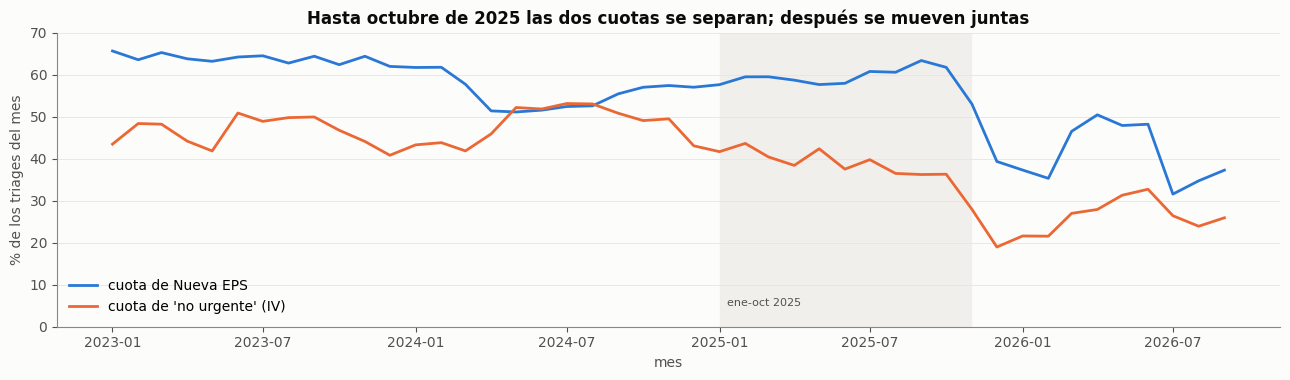

medias por tramo:
  2024                   {'% Nueva EPS': 55.6, '% no urgente': 48.1}
  ene-oct 2025           {'% Nueva EPS': 59.8, '% no urgente': 39.3}
  dic-2025 a feb-2026    {'% Nueva EPS': 37.3, '% no urgente': 20.7}
  mar-jun 2026           {'% Nueva EPS': 48.3, '% no urgente': 29.7}
  jul-sep 2026           {'% Nueva EPS': 34.5, '% no urgente': 25.4}

correlación mensual entre las dos cuotas: nov-2025 a sep-2026 r = +0.63 (11 meses);  ene-2024 a oct-2025 r = -0.80 (22 meses)


In [16]:
ne_mes = (entidad.assign(ym=entidad["dia"].dt.to_period("M"), ne=np.where(entidad["grupo"] == "nueva_eps", entidad["n"], 0))
                 .groupby("ym")[["ne", "n"]].sum())
comp = pd.DataFrame({"% Nueva EPS": 100 * ne_mes["ne"] / ne_mes["n"],
                     "% no urgente": cuota["no urgente"]}).dropna()
comp = comp.loc["2023-01":]

fig, ax = plt.subplots(figsize=(13, 3.9))
x = comp.index.to_timestamp()
ax.plot(x, comp["% Nueva EPS"], color=AZUL, lw=2, label="cuota de Nueva EPS")
ax.plot(x, comp["% no urgente"], color=NARANJA, lw=2, label="cuota de 'no urgente' (IV)")
ax.axvspan(pd.Timestamp("2025-01-01"), pd.Timestamp("2025-10-31"), color="#f0efec", zorder=0)
ax.text(pd.Timestamp("2025-01-10"), 5, "ene-oct 2025", fontsize=8, color=TINTA2)
ax.set_ylim(0, 70); ax.set_ylabel("% de los triages del mes"); ax.set_xlabel("mes"); ax.grid(axis="y")
ax.set_title("Hasta octubre de 2025 las dos cuotas se separan; después se mueven juntas")
ax.legend(loc="lower left")
plt.tight_layout(); plt.show()

def tramo(a0, a1):
    t = comp.loc[a0:a1]; return t.mean().round(1).to_dict()
print("medias por tramo:")
for a0, a1, nom in [("2024-01", "2024-12", "2024"), ("2025-01", "2025-10", "ene-oct 2025"),
                    ("2025-12", "2026-02", "dic-2025 a feb-2026"), ("2026-03", "2026-06", "mar-jun 2026"),
                    ("2026-07", "2026-09", "jul-sep 2026")]:
    print(f"  {nom:<22} {tramo(a0, a1)}")
r_desde = comp.loc["2025-11":].corr().iloc[0, 1]
r_antes = comp.loc["2024-01":"2025-10"].corr().iloc[0, 1]
print(f"\ncorrelación mensual entre las dos cuotas: nov-2025 a sep-2026 r = {r_desde:+.2f} ({len(comp.loc['2025-11':])} meses);"
      f"  ene-2024 a oct-2025 r = {r_antes:+.2f} ({len(comp.loc['2024-01':'2025-10'])} meses)")

### Lectura

**Son dos fenómenos, y solo el segundo tramo los junta.**

- **Enero a octubre de 2025: el criterio cambia solo.** La cuota de «no urgente» baja del 48,1 % de 2024 al 39,3 % mientras la cuota de Nueva EPS **sube** de 55,6 a 59,8 %. Entre enero de 2024 y octubre de 2025 las dos cuotas van en sentido contrario (r = −0,80, 22 meses).
- **Desde noviembre de 2025 las dos cuotas se mueven juntas.** En diciembre de 2025 a febrero de 2026, con Nueva EPS en 37,3 %, «no urgente» está en 20,7 %; en marzo a junio de 2026, con Nueva EPS en 48,3 %, sube a 29,7 %; y en julio a septiembre de 2026, con Nueva EPS en 34,5 %, baja a 25,4 %. La correlación mensual de noviembre de 2025 a septiembre de 2026 es de **r = +0,63** (11 meses).

**Hipótesis, no conclusión:** si lo que el hospital dejó de atender de Nueva EPS fue sobre todo lo no urgente (lo urgente se atiende por obligación legal), el desplome de noviembre explicaría a la vez la caída del volumen y la aceleración de la reclasificación. Contrastarlo exige el conteo por día, nivel y grupo de entidad.

### Límites

- Dos cuotas que se mueven juntas en once meses no son un desglose: no se sabe qué nivel tenían los pacientes de Nueva EPS que dejaron de venir.
- Con 11 puntos mensuales, un coeficiente de +0,63 es compatible con una relación débil, y los tramos de cada escalón no son independientes.
- La reclasificación de enero a octubre de 2025 puede tener su propia causa que solo conoce la institución.

---
# 6. La estancia y tres regímenes de medición

La diferencia entre la hora de salida y la hora de entrada al servicio da el tiempo que el paciente pasa registrado. La cobertura es alta y estable (91,1 % de los triages) y es la variable que más se acerca a la pregunta operativa de si hace falta más personal: un pico de consultas absorbido sin que suba la estancia no es saturación; uno que la sube, sí.

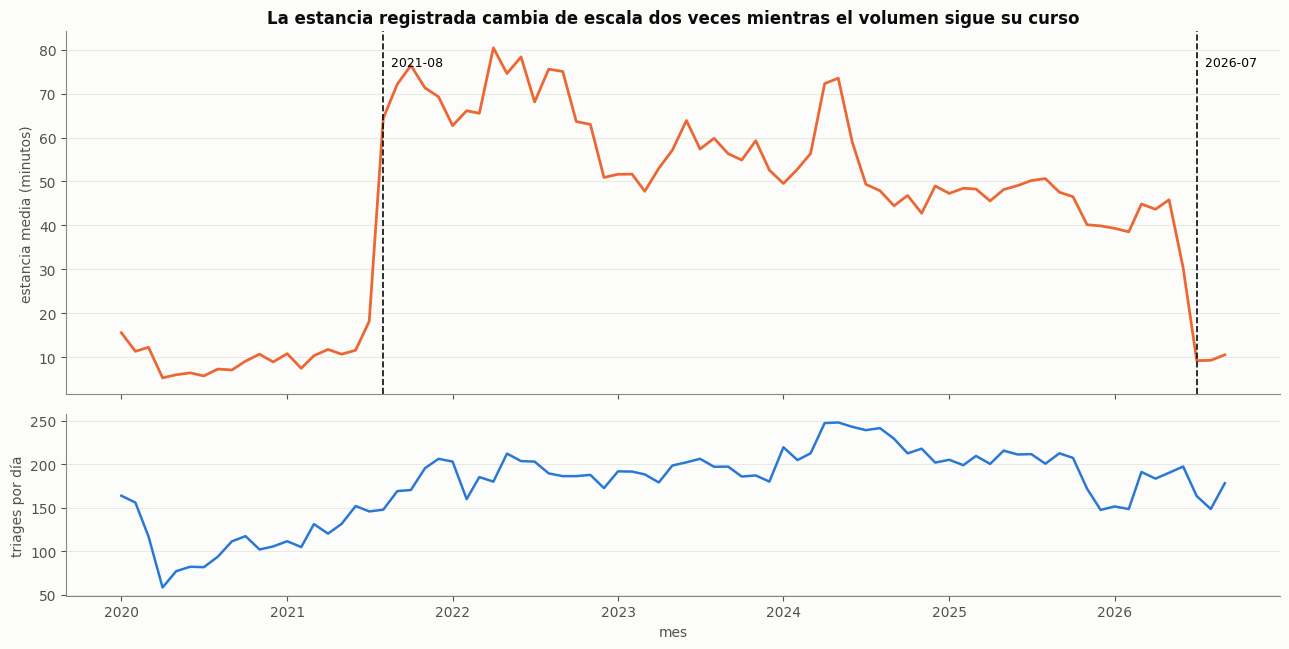

  régimen 1  2020-01 a 2021-07   estancia media   9.8 min   registros 58,211
  régimen 2  2021-08 a 2026-06   estancia media  55.8 min   registros 324,046
  régimen 3  2026-07 a 2026-09   estancia media   9.7 min   registros 12,458

media mensual en los dos saltos (min): {'2021-06': 11.6, '2021-07': 18.2, '2021-08': 64.4, '2021-09': 72.1} {'2026-05': 45.8, '2026-06': 30.4, '2026-07': 9.3, '2026-08': 9.3, '2026-09': 10.6}

cobertura por año (%): {2020: 85.5, 2021: 93.2, 2022: 93.6, 2023: 93.1, 2024: 90.1, 2025: 90.7, 2026: 88.7}
cobertura global: 91.1 %
media anual (min): {2020: 9.8, 2021: 41.7, 2022: 68.8, 2023: 55.5, 2024: 54.0, 2025: 47.2, 2026: 30.9}


In [17]:
est = estancia.set_index("dia").sort_index()
mens = est.resample("MS").apply(lambda d: np.average(d["media_min"], weights=d["n"])
                                if len(d) else np.nan)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 6.6), sharex=True,
                               gridspec_kw={"height_ratios": [2, 1]})
ax1.plot(mens.index, mens.to_numpy(), lw=2, color=NARANJA)
for corte, nota in [("2021-08-01", "2021-08"), ("2026-07-01", "2026-07")]:
    ax1.axvline(pd.Timestamp(corte), color=TINTA, lw=1.2, ls="--")
    ax1.text(pd.Timestamp(corte), mens.max() * 0.95, f"  {nota}", fontsize=9)
ax1.set_ylabel("estancia media (minutos)")
ax1.set_title("La estancia registrada cambia de escala dos veces mientras el volumen sigue su curso")
ax1.grid(axis="y")

vol = serie.resample("MS").mean()
ax2.plot(vol.index, vol.to_numpy(), lw=1.8, color=AZUL)
ax2.set_ylabel("triages por día"); ax2.set_xlabel("mes"); ax2.grid(axis="y")
plt.tight_layout(); plt.show()

for desde, hasta, nombre in [("2020-01", "2021-07", "régimen 1"),
                             ("2021-08", "2026-06", "régimen 2"),
                             ("2026-07", "2026-09", "régimen 3")]:
    v = mens.loc[desde:hasta]
    print(f"  {nombre}  {desde} a {hasta}   estancia media {v.mean():5.1f} min   registros {est.loc[desde:hasta, 'n'].sum():,}")
print("\nmedia mensual en los dos saltos (min):", {f"{k:%Y-%m}": round(v, 1) for k, v in mens.loc["2021-06":"2021-09"].items()},
      {f"{k:%Y-%m}": round(v, 1) for k, v in mens.loc["2026-05":"2026-09"].items()})

cob = est["n"].groupby(est.index.year).sum() / serie.groupby(serie.index.year).sum()
media_anual = est.groupby(est.index.year).apply(lambda d: np.average(d["media_min"], weights=d["n"]))
print("\ncobertura por año (%):", (100 * cob).round(1).to_dict())
print(f"cobertura global: {100 * est['n'].sum() / serie.sum():.1f} %")
print("media anual (min):", media_anual.round(1).to_dict())

### Lectura

**La estancia registrada tiene dos saltos bruscos que no son clínicos.**

| Régimen | Periodo | Estancia media | Registros |
|---|---|---|---|
| 1 | 2020-01 a 2021-07 | **9,8 min** | 58.211 |
| 2 | 2021-08 a 2026-06 | **55,8 min** | 324.046 |
| 3 | 2026-07 a 2026-09 | **9,7 min** | 12.458 |

La media mensual pasa de 18,2 minutos en julio de 2021 a 64,4 en agosto, y de 30,4 en junio de 2026 a 9,3 en julio. Esos saltos multiplican por 3,5 la media en un mes y la dividen por 3,3 en el otro. Un servicio de urgencias no cambia así su tiempo de atención: lo que cambió es qué se registra como hora de salida. Las comparaciones entre regímenes no miden nada comparable; por ejemplo, la media anual de 9,8 minutos en 2020 frente a 68,8 en 2022.

**Dentro del régimen 2 tampoco es estable.** La media anual baja de 68,8 (2022) a 55,5 (2023), 54,0 (2024) y 47,2 (2025), y ya estaba en 30,4 en junio de 2026, antes del tercer régimen. La variable solo es utilizable dentro del régimen 2 y con cautela, y este cuaderno no puede decir si sus variaciones son saturación o cambios de registro.

La cobertura por año va de 85,5 % (2020) a 93,6 % (2022), es decir, es estable y no introduce una tendencia.

**Método que se desprende de este caso y del nivel de urgencia:** antes de usar cualquier columna, mirar su serie mensual buscando escalones. Es la segunda deriva de medición hallada, después del criterio de nivel; el asegurador (sección 5.2) es un escalón de otra naturaleza, porque es demanda real que se va y vuelve.

### Límites

- Las medias diarias están recortadas a estancias entre 0 y 1.440 minutos, y un cambio en cuántos registros caen fuera de ese rango también movería la media.
- `triage_estancia.parquet` guarda solo la media y el máximo por día; no se pueden calcular medianas ni cuantiles desde este archivo.

---
# Conclusiones y límites

## Lo que muestran los datos

1. **La serie no crece de forma sostenida.** Pasa de 105,7 triages por día en 2020 a 226,9 en 2024 y cae a 172,6 en 2026, un −23,9 % desde el pico. Toda la caída es de demanda que dejó de llegar, no de reclasificación.
2. **Esa caída es de Nueva EPS** (−53,4 de los −54,2 triages por día entre 2024 y 2026), en dos escalones: noviembre de 2025 y julio de 2026. El resto de aseguradores queda igual y compensa solo entre el 13 y el 22 % de lo que pierde Nueva EPS. El pico de 2024 es de otro asegurador, EPS Sura.
3. **2020 es un cráter de COVID** (−64 % entre enero y abril) y la serie no recupera el nivel de enero de 2020 hasta septiembre de 2021.
4. **La estacionalidad anual es del 18-20 %**, con la demanda más alta de mayo a agosto, medida sobre tres ciclos completos.
5. **La hora manda más que el día de la semana:** 13,9 veces de oscilación frente a 1,57. El día tiene dos jorobas (10-11 h y 14-15 h), y el domingo tiene otra forma, no solo menos volumen. Estas formas son estables entre 2022-2024 y 2025-2026.
6. **El criterio de clasificación por nivel derivó desde enero de 2025**, y desde noviembre de 2025 se mueve junto con la cuota de Nueva EPS. Más de la mitad de los triages son no urgentes y las emergencias son el 0,37 %.
7. **La estancia registrada cambió de escala dos veces** (agosto de 2021 y julio de 2026) y no sirve para comparar años.
8. **Hay un hueco de registro**, el 19-21 de marzo de 2024, que se trata como dato ausente.

## Qué implica para el modelo

- El control de calendario necesita la hora, con dos o tres armónicos, si el pronóstico es horario; para el pronóstico diario basta el día de la semana.
- **El estado de Nueva EPS tiene que entrar como variable.** Más que elegir una ventana de entrenamiento «limpia», hay que reconocer que en abril de 2024 salta otro asegurador y desde noviembre de 2025 Nueva EPS cae en escalones.
- 2020 no entra sin tratamiento aparte, y los tres días de marzo de 2024 van como nulo.
- Cualquier variable nueva debe auditarse mirando su serie mensual antes de usarla.

## Límites del análisis

- Este cuaderno describe la serie; no mide ningún efecto externo y no puede decir qué mueve los picos alrededor del nivel.
- No se puede separar la reclasificación de un cambio en la composición de pacientes sin el cruce día × nivel × asegurador.
- La causa de los escalones de Nueva EPS (contratación, intervención, barrera de acceso) está por fuera de los datos; las fechas de los eventos entre el hospital y la aseguradora no están en ellos.
- La estacionalidad se estima con tres ciclos completos y mezcla calendario con cualquier otro factor.
- La estancia solo se puede interpretar dentro de un régimen de medición, y aun así deriva.

## Relación con otros cuadernos

El cuaderno 02 examina la edad y el asegurador como familias de variables del hospital; el 06 fija la regla de caídas de registro aplicada aquí y encuentra que siete de las diez semanas más bajas caen entre noviembre de 2025 y febrero de 2026; el 07 explica esas semanas por el desplome de Nueva EPS; el 18 amplía el análisis a todos los aseguradores con afiliados y resoluciones.